# VCO(電圧制御発振器)

入力の電圧で**周波数が変わる**発振器です。VCO(Voltage-Controlled Oscillator)といいます。周波数を電圧で調整したいところ(シンセサイザーの音の高さ、ラジオの選局、PLL による周波数の合成)や、電圧を周波数に変えて送る・数えるところ(6-5 の V/F 変換)で使います。

この回では、入力の電圧と周波数の関係、入力を動かして周波数を振る(周波数変調、FM)、周波数が 0 で止まるところ、の 3 つを見ます。

## 回路

![VCO(ブロック図)](02_vco/circuit.svg)

6-1 の関数発生器で、積分器に入れる電圧を、方形波そのもの($\pm V_s$)ではなく「入力の電圧 × 方形波の向き($\pm 1$)」にしたものです。入力が大きいほど三角波の傾きが急になり、しきい値に早く届くので、周波数が上がります。実際の回路では、アナログスイッチやトランジスタで、入力の電圧の向きを方形波に合わせて切り替えます。

## 原理

6-1 の式で $V_s$ を入力の電圧 $V_\mathrm{in}$ に置きかえると、周期 $T = 4RC\,V_\mathrm{th}/V_\mathrm{in}$ で、**周波数は入力に比例**します。

$$f = \frac{V_\mathrm{in}}{4RC\,V_\mathrm{th}} \quad\to\quad \text{Mimic:}\quad f = f_0 + k\,(V_\mathrm{in} - V_\mathrm{ref})$$

Mimic の VCO は、入力が Vref のときの周波数 $f_0$ と、1 V あたりの周波数の変化 $k$(Hz/V、**感度**)で決めます。周波数は 0 Hz より下にはならず、0 Hz では出力が止まります(そのときの値のまま)。

| 入力 | 出力 |
|---|---|
| 一定の電圧 | 一定の周波数の波 |
| ゆっくり変わる電圧 | 周波数がそれに合わせて変わる波(周波数変調、FM) |
| $f_0 + k(V_\mathrm{in}-V_\mathrm{ref}) < 0$ になる電圧 | 止まる |

シンセサイザーの VCO は、1 V で周波数が 2 倍(1 オクターブ)になる「指数」の特性を使います。Mimic の VCO は直線なので、前に ANTILOG(第 4 弾)をつなぐと指数になります。

![VCO の入力と周波数(模式図)](02_vco/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.vco(f0, k, amp, wave)` | `mimic.setVco(f0, k, amp, MIMIC_OSC_WAVE_SINE)` など | Vref での周波数 $f_0$(Hz)、感度 $k$(Hz/V、負なら入力が上がると周波数が下がる)、振幅(V)、波形(6-1 と同じ) |

- 周波数の上限は 100 kHz です。測定器で見るには、数 Hz〜1 kHz 程度にします。
- 下の準備のセルの `inst_freq` は、出力の 1 周期ごとの周波数を、立ち上がりの時刻の間隔から求めます。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, measure

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.4, mimic=20261125)

In [2]:
def inst_freq(t, v):
    # Frequency of each period, from the rising crossings of the middle: (times, Hz)
    mid = (v.max() + v.min()) / 2
    i = np.flatnonzero((v[:-1] < mid) & (v[1:] >= mid))
    tc = t[i] + (mid - v[i]) / (v[i + 1] - v[i]) * (t[1] - t[0])
    return (tc[1:] + tc[:-1]) / 2, 1 / np.diff(tc)


def show_fm(t, ch1, ch2, label):
    # Waveforms (top) and the frequency of each period with the input (bottom)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
    ax1.plot(t * 1e3, ch1, label="CH1: input")
    ax1.plot(t * 1e3, ch2, lw=0.8, label=f"CH2: output ({label})")
    ax1.set_ylabel("Voltage [V]")
    ax1.legend(loc="upper right")
    tf, f = inst_freq(t, ch2)
    ax2.plot(tf * 1e3, f, ".-", color="C1", label="frequency of each period")
    ax2.set_ylabel("Frequency [Hz]")
    ax2.set_xlabel("Time [ms]")
    ax2.legend(loc="upper right")
    for ax in (ax1, ax2):
        ax.grid(True)
    plt.show()

## 実験 1:入力の電圧と周波数

$f_0$ = 500 Hz、$k$ = 200 Hz/V にして、入力の直流を 1.5〜3.5 V まで変えながら周波数を測ります。周波数は 300〜700 Hz の直線になるはずです。それぞれの入力で取り込んだ波形の最初の 10 ms を並べてから、入力と周波数のグラフにします。

input 1.501 V:   300.7 Hz (theory   300.2 Hz)
input 2.000 V:   401.0 Hz (theory   400.0 Hz)
input 2.501 V:   501.5 Hz (theory   500.2 Hz)
input 3.001 V:   601.9 Hz (theory   600.3 Hz)
input 3.500 V:   702.2 Hz (theory   700.1 Hz)


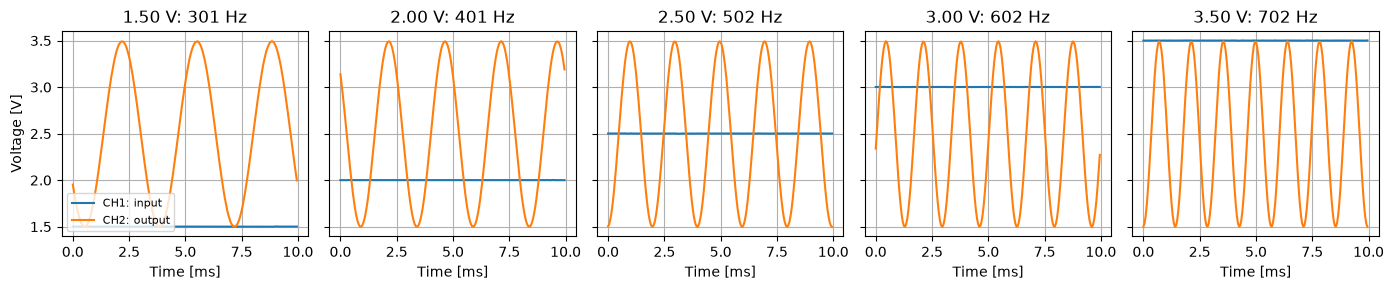

sensitivity from the measurement: 200.8 Hz/V (setting 200 Hz/V)


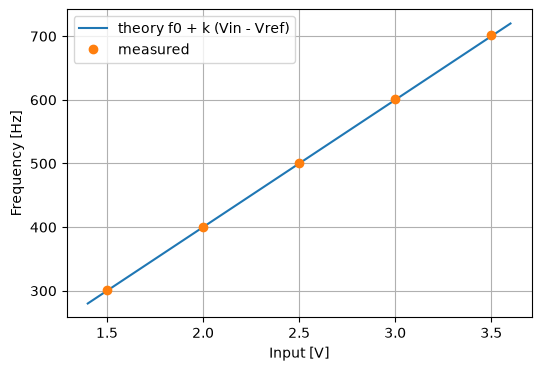

In [3]:
F0, K = 500, 200   # [Hz], [Hz/V]
inputs = (1.5, 2.0, 2.5, 3.0, 3.5)

lab.mimic.vco(F0, K, 1.0)
vin, freq = [], []
fig, axes = plt.subplots(1, len(inputs), figsize=(14, 3), sharey=True)
for ax, v in zip(axes, inputs):
    lab.fg.dc(v)
    time.sleep(0.1)
    t, ch1, ch2 = lab.scope.capture(2000)
    vin.append(ch1.mean())
    freq.append(measure(t, ch2)[1])
    print(f"input {vin[-1]:.3f} V: {freq[-1]:7.1f} Hz (theory {F0 + K * (vin[-1] - 2.5):7.1f} Hz)")
    n = t < 0.01
    ax.plot(t[n] * 1e3, ch1[n], label="CH1: input")
    ax.plot(t[n] * 1e3, ch2[n], label="CH2: output")
    ax.set_title(f"{vin[-1]:.2f} V: {freq[-1]:.0f} Hz")
    ax.set_xlabel("Time [ms]")
    ax.grid(True)
axes[0].set_ylabel("Voltage [V]")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

vin, freq = np.array(vin), np.array(freq)
slope = np.polyfit(vin, freq, 1)[0]
print(f"sensitivity from the measurement: {slope:.1f} Hz/V (setting {K} Hz/V)")
fig, ax = plt.subplots(figsize=(6, 4))
v_th = np.linspace(1.4, 3.6, 50)
ax.plot(v_th, F0 + K * (v_th - 2.5), "-", label="theory f0 + k (Vin - Vref)")
ax.plot(vin, freq, "o", label="measured")
ax.set_xlabel("Input [V]")
ax.set_ylabel("Frequency [Hz]")
ax.grid(True)
ax.legend()
plt.show()

理論の線は、Vref をちょうど 2.5 V として計算しています。測った点は、Mimic と Arduino の時計の違い(6-1)のぶん、わずかにずれることがあります。

## 実験 2:周波数を振る(FM)

入力に 5 Hz、振幅 1 V の三角波を入れます。周波数は、入力に合わせて 300 Hz と 700 Hz のあいだを行き来するはずです。10 kHz で 0.2 秒(入力の 1 周期)取り込みます。

frequency 305 - 700 Hz (theory 300 - 700 Hz)


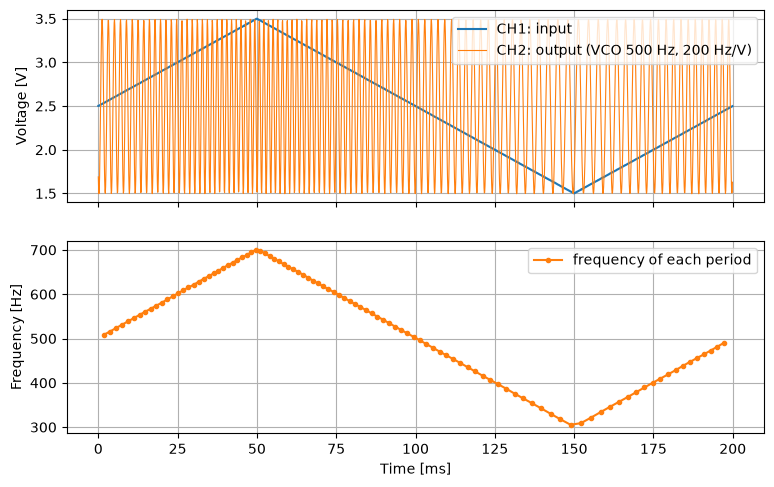

In [4]:
lab.fg.triangle(5, 1.0)
lab.mimic.vco(500, 200, 1.0)
time.sleep(0.2)
t, ch1, ch2 = lab.scope.capture(2000, fs=10000)   # 0.2 s
tf, f = inst_freq(t, ch2)
print(f"frequency {f.min():.0f} - {f.max():.0f} Hz (theory 300 - 700 Hz)")
show_fm(t, ch1, ch2, "VCO 500 Hz, 200 Hz/V")

出力の波は、入力が高いところで細かく(周波数が高く)、低いところで粗く(周波数が低く)なります。下のグラフの 1 周期ごとの周波数は、入力の三角波と同じ形です(1 周期のあいだの平均なので、山と谷では理論の 300、700 Hz より少し内側になります)。FM ラジオは、音の電圧でこのように搬送波の周波数を振って送っています。

## 実験 3:0 Hz で止まる

$f_0$ = 200 Hz、$k$ = 200 Hz/V にして、振幅 1.5 V の三角波を入れます。入力が 1.5 V(Vref − 1 V)より下では、周波数は 0 Hz で頭打ちになり、出力は止まるはずです。

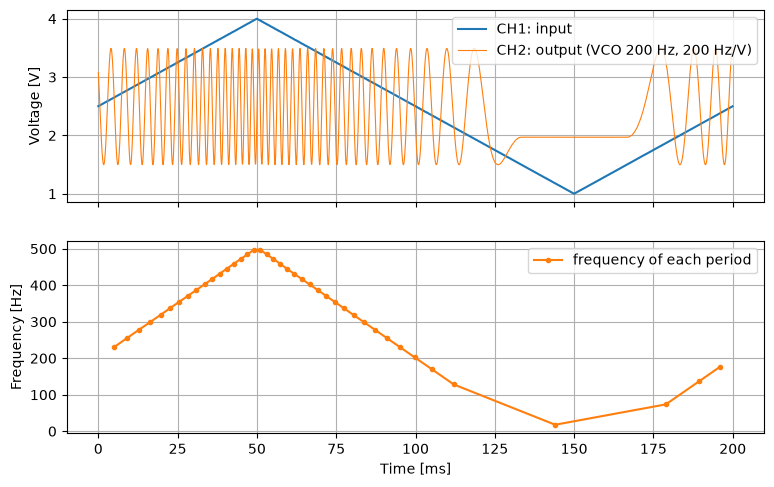

In [5]:
lab.fg.triangle(5, 1.5)
lab.mimic.vco(200, 200, 1.0)
time.sleep(0.2)
t, ch1, ch2 = lab.scope.capture(2000, fs=10000)
show_fm(t, ch1, ch2, "VCO 200 Hz, 200 Hz/V")

入力が 1.5 V より下のあいだ、出力はそのときの値で止まり、入力が戻ると同じ位相から再び動き出します。周波数の計算が 0 より下にならないように、Mimic が頭打ちにしているためです。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 感度を変える
<details><summary>ヒント</summary>

`K` を 400 → −200 → 50 と変えてみましょう(実験 2 は 200)。

- 400:周波数は 100〜900 Hz と、大きく振れます。
- −200:入力が上がると周波数が**下がり**ます(下のグラフが入力と逆の形)。
- 50:450〜550 Hz と、わずかしか振れません。

</details>

frequency 117 - 901 Hz (theory 100 - 900 Hz)


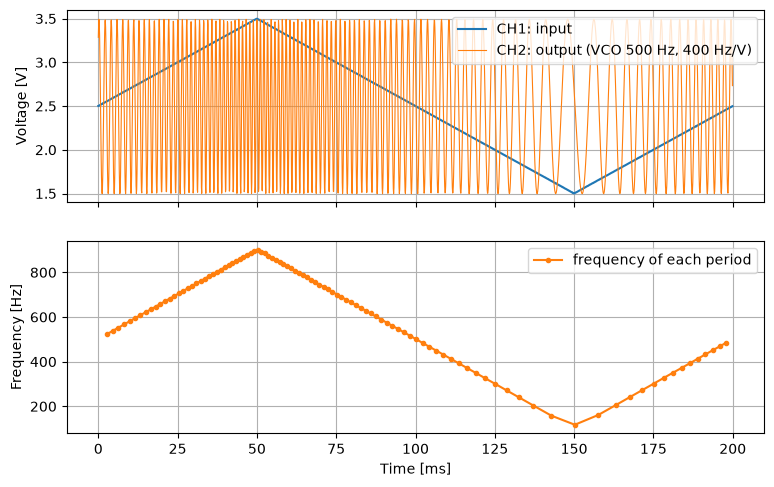

In [6]:
K = 400   # [Hz/V]

lab.fg.triangle(5, 1.0)
lab.mimic.vco(500, K, 1.0)
time.sleep(0.2)
t, ch1, ch2 = lab.scope.capture(2000, fs=10000)
tf, f = inst_freq(t, ch2)
print(f"frequency {f.min():.0f} - {f.max():.0f} Hz (theory {500 - abs(K):.0f} - {500 + abs(K):.0f} Hz)")
show_fm(t, ch1, ch2, f"VCO 500 Hz, {K} Hz/V")

### 2. 波形を変える
<details><summary>ヒント</summary>

`WAVE` を `"square"` → `"triangle"` → `"sawtooth"` と変えてみましょう。どの波形でも、周波数の変わり方は同じです。方形波にすると、6-5 の V/F 変換器の出力(デジタル)とほぼ同じものが、アナログの出力から出ます。

方形波では、下のグラフの 1 周期ごとの周波数ががたがたします。これは測定器の限界です。方形波は縁が急なので、取り込みの点と点のあいだ(10 kHz なら 0.1 ms)のどこで切り替わったかがわからず、1 周期の時間が ±0.05 ms ほどぶれます(500 Hz なら周波数で ±数 %)。正弦波や三角波は縁がなだらかなので、点のあいだを補間して正確に求められます。Mimic の周波数そのものは正しく、何周期かを平均すれば合います。

</details>

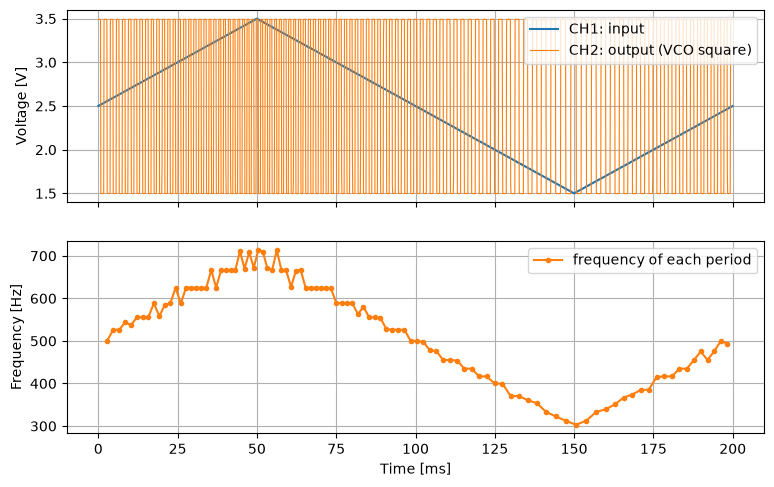

In [7]:
WAVE = "square"

lab.fg.triangle(5, 1.0)
lab.mimic.vco(500, 200, 1.0, WAVE)
time.sleep(0.2)
t, ch1, ch2 = lab.scope.capture(2000, fs=10000)
show_fm(t, ch1, ch2, f"VCO {WAVE}")

## まとめ

- VCO は、入力の電圧で周波数が変わる発振器。関数発生器の積分器に入れる電圧を入力に比例させると、周波数が入力に比例する。
- Mimic の VCO は $f = f_0 + k(V_\mathrm{in} - V_\mathrm{ref})$。入力を動かすと周波数が振れる(FM)。0 Hz より下では止まる。
- Mimic では `vco(f0, k, amp, wave)`。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [8]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()